# 13 · Probability & Statistics for ML — Learned by Simulation

Machine learning is built on probability: models output probabilities, losses come from likelihoods, and every evaluation number (an accuracy, an A/B-test lift) is an **estimate** with uncertainty around it. This notebook teaches the essentials by **simulating** them. Instead of trusting a formula, we generate thousands of random worlds and watch the formula come true.

**What you'll learn**
1. Probability by counting simulated outcomes; conditional probability; **Bayes' rule** and the base-rate trap
2. Random variables and the **distributions** that keep appearing in ML
3. The **law of large numbers** and the **central limit theorem**
4. **Maximum likelihood (MLE)** and **MAP** — and why MSE and log-loss are what they are
5. **Confidence intervals** (what they really mean) and the **bootstrap**
6. **Hypothesis tests** and p-values: permutation tests, t-tests
7. **A/B testing:** two-proportion tests, **power and sample size**, the peeking problem
8. **Multiple testing:** Bonferroni and Benjamini–Hochberg
9. **Bayesian A/B testing**
10. Correlation vs causation: **Simpson's paradox**

Each idea is shown 🐍 in pure Python → 🔢 with NumPy → 📦 with SciPy/statsmodels.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from scipy import stats
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); random.seed(0)

## 1. Probability by simulation

The probability of an event = the fraction of times it happens if you repeat the experiment many, many times. That's something a computer can do directly.

**Example:** roll two dice. What's P(sum = 7)? Exact answer: 6 of 36 outcomes → 1/6 ≈ 0.1667.

In [2]:
# 🐍 Pure Python
trials = 100_000
hits = sum(1 for _ in range(trials) if random.randint(1, 6) + random.randint(1, 6) == 7)
print(f"pure Python: {hits / trials:.4f}")

# 🔢 NumPy — a million rolls at once
rolls = rng.integers(1, 7, size=(1_000_000, 2))
print(f"NumPy:       {np.mean(rolls.sum(1) == 7):.4f}   exact: {1/6:.4f}")

pure Python: 0.1704
NumPy:       0.1668   exact: 0.1667


### Conditional probability
$P(A \mid B)$ = probability of A **given** that B happened = $\frac{P(A \text{ and } B)}{P(B)}$. In simulation: **keep only the trials where B happened**, then count A.

*Given that at least one die shows a 6, what's P(sum ≥ 10)?*

In [3]:
B = (rolls == 6).any(axis=1)
A = rolls.sum(1) >= 10
print(f"P(sum ≥ 10)              = {A.mean():.4f}")
print(f"P(sum ≥ 10 | a six shows) = {A[B].mean():.4f}   (exact 5/11 = {5/11:.4f})")

P(sum ≥ 10)              = 0.1666
P(sum ≥ 10 | a six shows) = 0.4539   (exact 5/11 = 0.4545)


### Bayes' rule and the base-rate trap
$$ P(H \mid E) = \frac{P(E \mid H)\,P(H)}{P(E)} $$

**Classic puzzle:** a disease affects 1% of people. A test catches 95% of sick people (sensitivity) and wrongly flags 5% of healthy people (false-positive rate). **You test positive. What's the chance you're sick?**

Most people guess ~95%. Let's simulate a population.

In [4]:
# 🐍 Pure Python: simulate 100,000 people
people = 100_000; sick_pos = healthy_pos = 0
for _ in range(people):
    sick = random.random() < 0.01
    positive = random.random() < (0.95 if sick else 0.05)
    if positive and sick: sick_pos += 1
    if positive and not sick: healthy_pos += 1
print(f"positives: {sick_pos} sick + {healthy_pos} healthy → P(sick | positive) ≈ {sick_pos / (sick_pos + healthy_pos):.3f}")

# Bayes' rule
p_pos = 0.95 * 0.01 + 0.05 * 0.99
print(f"Bayes' rule: 0.95 × 0.01 / {p_pos:.4f} = {0.95 * 0.01 / p_pos:.3f}")

positives: 969 sick + 5040 healthy → P(sick | positive) ≈ 0.161
Bayes' rule: 0.95 × 0.01 / 0.0590 = 0.161


Only ~16%! Because the disease is rare, the 5% false alarms among the 99% healthy people vastly outnumber the true positives. **The base rate (prior) matters enormously.** This is exactly why precision is low when you predict rare events (fraud, notebook 03) even with a good model.

## 2. Random variables and distributions

A **random variable** is a number produced by a random process. Its **distribution** says how likely each value is: a **PMF** (probability mass function) for discrete values, a **PDF** (density) for continuous ones, and the **CDF** $F(x) = P(X \le x)$ for both.

| Distribution | Models | Mean | Variance | Where it shows up in ML |
|---|---|---|---|---|
| **Bernoulli(p)** | one yes/no | p | p(1−p) | binary labels; logistic regression's output |
| **Binomial(n, p)** | # successes in n tries | np | np(1−p) | conversions in an A/B test |
| **Poisson(λ)** | counts of rare events | λ | λ | clicks per hour, support calls (notebook 08) |
| **Normal(μ, σ²)** | sums of many small effects | μ | σ² | noise in regression; the CLT |
| **Exponential(λ)** | waiting times | 1/λ | 1/λ² | time between events |
| **Uniform(a, b)** | "anything in range" | (a+b)/2 | (b−a)²/12 | random initialisation, random search |
| **Beta(α, β)** | a probability itself | α/(α+β) | — | priors for rates (Bayesian A/B) |

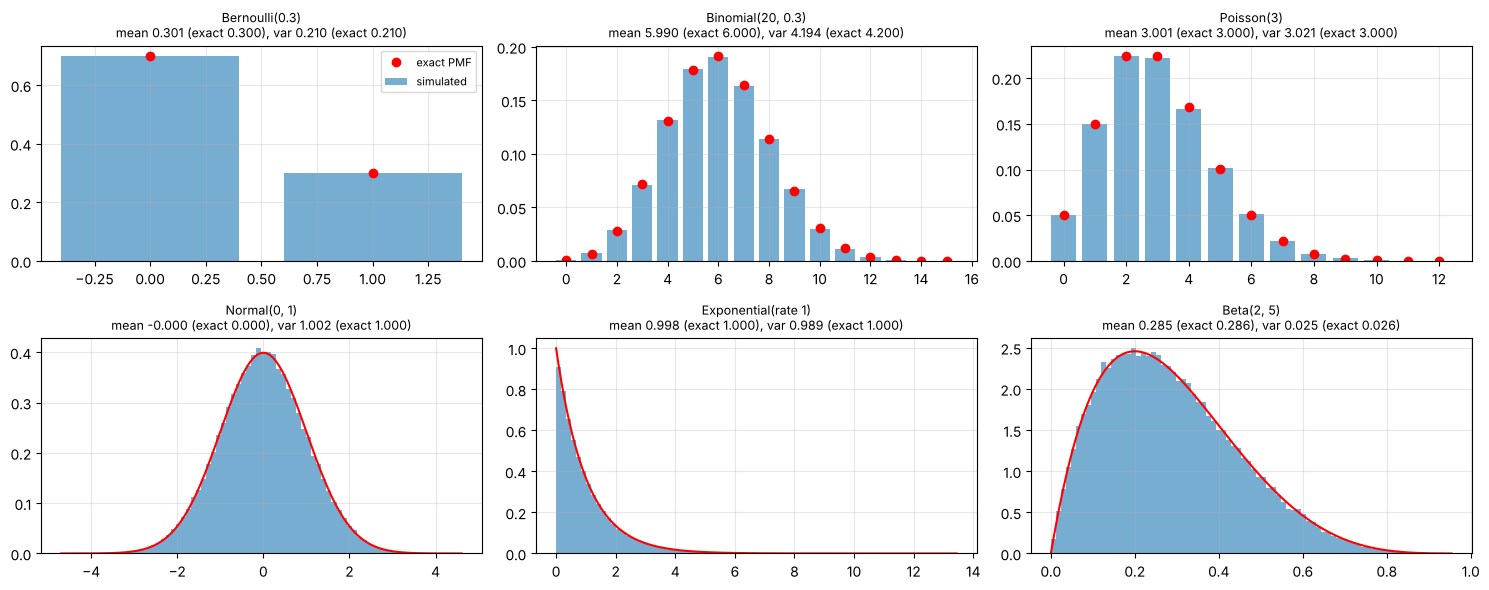

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
samples = {
    "Bernoulli(0.3)": rng.binomial(1, 0.3, 100_000), "Binomial(20, 0.3)": rng.binomial(20, 0.3, 100_000),
    "Poisson(3)": rng.poisson(3, 100_000), "Normal(0, 1)": rng.normal(0, 1, 100_000),
    "Exponential(rate 1)": rng.exponential(1, 100_000), "Beta(2, 5)": rng.beta(2, 5, 100_000),
}
dists = {"Bernoulli(0.3)": stats.bernoulli(0.3), "Binomial(20, 0.3)": stats.binom(20, 0.3), "Poisson(3)": stats.poisson(3),
         "Normal(0, 1)": stats.norm(0, 1), "Exponential(rate 1)": stats.expon(scale=1), "Beta(2, 5)": stats.beta(2, 5)}
for ax, (name, x) in zip(axes.ravel(), samples.items()):
    d = dists[name]
    if name in ("Bernoulli(0.3)", "Binomial(20, 0.3)", "Poisson(3)"):
        vals, counts = np.unique(x, return_counts=True)
        ax.bar(vals, counts / len(x), alpha=0.6, label="simulated"); ax.plot(vals, d.pmf(vals), "ro", label="exact PMF")
    else:
        ax.hist(x, bins=80, density=True, alpha=0.6, label="simulated"); g = np.linspace(x.min(), x.max(), 300); ax.plot(g, d.pdf(g), "r", label="exact PDF")
    ax.set_title(f"{name}\nmean {x.mean():.3f} (exact {d.mean():.3f}), var {x.var():.3f} (exact {d.var():.3f})", fontsize=9)
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Expectation and variance
$$ E[X] = \sum_x x\,P(X = x), \qquad \text{Var}(X) = E\big[(X - E[X])^2\big] = E[X^2] - E[X]^2 $$
Two rules you'll use constantly:
- **Linearity:** $E[aX + bY] = aE[X] + bE[Y]$ — always, even if X and Y are dependent.
- For **independent** X, Y: $\text{Var}(X + Y) = \text{Var}(X) + \text{Var}(Y)$. So the average of n independent copies has variance $\sigma^2 / n$ — the reason averaging (bagging, ensembles, bigger samples) reduces noise.

In [6]:
# 🐍 E[X] and Var(X) of a fair die from the definition, vs simulation
faces = [1, 2, 3, 4, 5, 6]
E = sum(x * (1 / 6) for x in faces); V = sum((x - E) ** 2 * (1 / 6) for x in faces)
print(f"die: E = {E:.4f}, Var = {V:.4f} | simulated E = {rolls[:, 0].mean():.4f}, Var = {rolls[:, 0].var():.4f}")

# Variance of an average shrinks like σ²/n
for n in [1, 4, 16, 64]:
    means = rng.integers(1, 7, size=(100_000, n)).mean(1)
    print(f"average of {n:2d} dice: variance {means.var():.4f}  (σ²/n = {V / n:.4f})")

die: E = 3.5000, Var = 2.9167 | simulated E = 3.5012, Var = 2.9176
average of  1 dice: variance 2.9098  (σ²/n = 2.9167)
average of  4 dice: variance 0.7269  (σ²/n = 0.7292)
average of 16 dice: variance 0.1816  (σ²/n = 0.1823)
average of 64 dice: variance 0.0454  (σ²/n = 0.0456)


## 3. The law of large numbers and the central limit theorem

**Law of large numbers (LLN):** the sample average converges to the true mean as the sample grows. That's why estimates from more data are better.

**Central limit theorem (CLT):** the *average* of many independent draws is approximately **normally distributed**, with mean μ and standard deviation $\sigma/\sqrt{n}$ — **whatever the original distribution looks like** (as long as its variance is finite). This is why the normal distribution is everywhere, and why confidence intervals and A/B tests work.

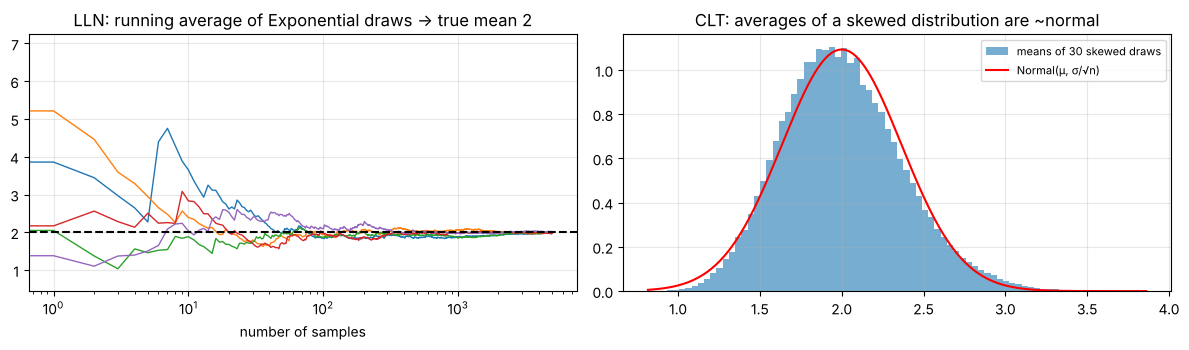

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k in range(5):
    x = rng.exponential(2.0, 5000)
    ax[0].plot(np.cumsum(x) / np.arange(1, 5001), lw=1)
ax[0].axhline(2.0, c="k", ls="--"); ax[0].set_xscale("log"); ax[0].set_xlabel("number of samples")
ax[0].set_title("LLN: running average of Exponential draws → true mean 2")

x = rng.exponential(2.0, (100_000, 30)).mean(1)
ax[1].hist(x, bins=80, density=True, alpha=0.6, label="means of 30 skewed draws")
g = np.linspace(x.min(), x.max(), 300); ax[1].plot(g, stats.norm(2, 2 / np.sqrt(30)).pdf(g), "r", label="Normal(μ, σ/√n)")
ax[1].legend(fontsize=8); ax[1].set_title("CLT: averages of a skewed distribution are ~normal")
plt.tight_layout(); plt.show()

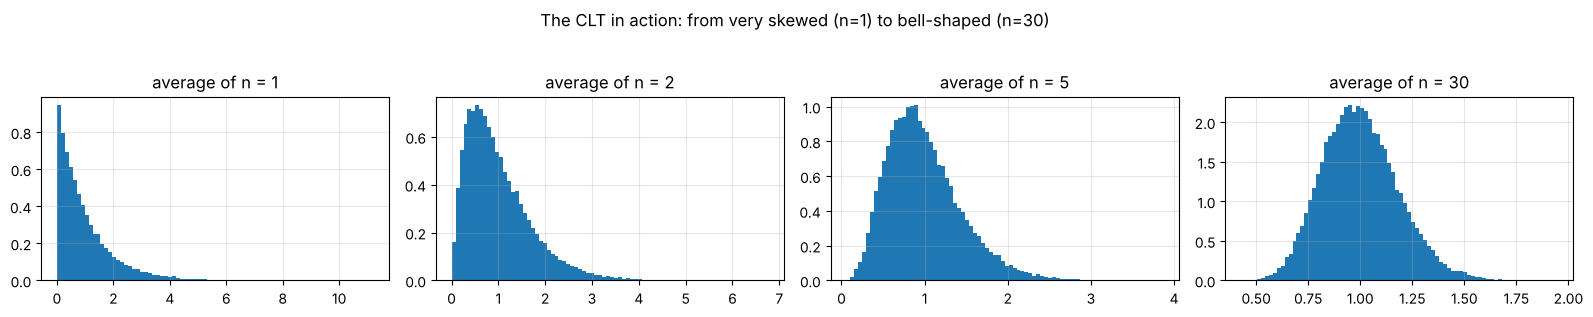

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, n in zip(axes, [1, 2, 5, 30]):
    ax.hist(rng.exponential(1, (50_000, n)).mean(1), bins=80, density=True); ax.set_title(f"average of n = {n}")
plt.suptitle("The CLT in action: from very skewed (n=1) to bell-shaped (n=30)", y=1.04); plt.tight_layout(); plt.show()

⚠️ The CLT needs finite variance and enough samples. With **heavy tails** (a few huge values — revenue per user, file sizes) "enough" can mean thousands, and averages stay erratic. The bootstrap (Section 5) and robust statistics (median) help.

## 4. Estimation: maximum likelihood (MLE) and MAP

You flip a coin 10 times and see 7 heads. What's your best estimate of p, the probability of heads?

The **likelihood** $L(p)$ = the probability of the observed data if the true value were p. **MLE** picks the p that makes the data most likely. We maximise the **log-likelihood** (sums are easier than products, and the maximum is in the same place):
$$ \log L(p) = 7\log p + 3\log(1-p) $$

grid-search MLE: p = 0.7  (calculus: set the derivative to 0 → p = heads/n = 0.7)


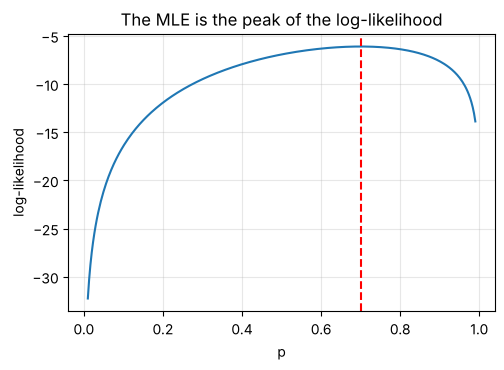

In [9]:
# 🐍 Pure Python: MLE by brute-force search over a grid of p
heads, n_flips = 7, 10
def log_lik(p): return heads * math.log(p) + (n_flips - heads) * math.log(1 - p)
grid = [i / 1000 for i in range(1, 1000)]
p_mle = max(grid, key=log_lik)
print(f"grid-search MLE: p = {p_mle}  (calculus: set the derivative to 0 → p = heads/n = {heads / n_flips})")

ps = np.linspace(0.01, 0.99, 300)
plt.plot(ps, [log_lik(p) for p in ps]); plt.axvline(0.7, ls="--", c="r")
plt.xlabel("p"); plt.ylabel("log-likelihood"); plt.title("The MLE is the peak of the log-likelihood"); plt.show()

### MLE is where ML's loss functions come from
- Assume $y = f(x) + \varepsilon$ with **Gaussian** noise. Maximising the likelihood = minimising $\sum (y - f(x))^2$ → **MSE** (notebook 01).
- Assume $y \sim \text{Bernoulli}(p(x))$. Maximising the likelihood = minimising $-\sum [y\log p + (1-y)\log(1-p)]$ → **log-loss** (notebook 02).
- Assume **Laplace** noise → minimise $\sum |y - f(x)|$ → **MAE**.

So choosing a loss function *is* choosing an assumption about the noise.

In [10]:
# 🔢 Check: for Gaussian noise, the MLE of the mean and std have closed forms (sample mean, and std with 1/n)
data = rng.normal(5.0, 2.0, 200)
mu_hat, sigma_hat = data.mean(), data.std(ddof=0)
print(f"closed-form MLE: μ = {mu_hat:.3f}, σ = {sigma_hat:.3f}")
print(f"scipy.stats.norm.fit (numerical MLE): μ = {stats.norm.fit(data)[0]:.3f}, σ = {stats.norm.fit(data)[1]:.3f}")

closed-form MLE: μ = 5.206, σ = 2.053
scipy.stats.norm.fit (numerical MLE): μ = 5.206, σ = 2.053


### Bias: why the sample variance divides by n − 1
The MLE of the variance, $\frac{1}{n}\sum (x - \bar x)^2$, is **biased** — on average it's too small, because $\bar x$ is fitted to the same data and sits closer to it than the true mean does. Dividing by $n - 1$ ("Bessel's correction") fixes the bias. Simulation:

In [11]:
n_small = 5; true_var = 4.0
samples_ = rng.normal(0, 2, (200_000, n_small))
print(f"average of 1/n   estimates: {samples_.var(axis=1, ddof=0).mean():.3f}  (biased, ≈ (n−1)/n × 4 = {(n_small - 1) / n_small * 4:.2f})")
print(f"average of 1/(n−1) estimates: {samples_.var(axis=1, ddof=1).mean():.3f}  (unbiased, true = {true_var})")

average of 1/n   estimates: 3.199  (biased, ≈ (n−1)/n × 4 = 3.20)
average of 1/(n−1) estimates: 3.999  (unbiased, true = 4.0)


### MAP: adding prior beliefs
With 2 flips both heads, MLE says p = 1.0 — absurdly confident. **MAP** (maximum a posteriori) maximises *likelihood × prior*. With a **Beta(a, b)** prior on p (think "a−1 imaginary heads and b−1 imaginary tails"), the MAP estimate is
$$ \hat p_{MAP} = \frac{\text{heads} + a - 1}{n + a + b - 2} $$
A prior acts like **regularisation**: in fact, L2 regularisation (Ridge) = MAP with a Gaussian prior on the weights, and L1 (Lasso) = MAP with a Laplace prior.

In [12]:
for h, n_ in [(2, 2), (7, 10), (700, 1000)]:
    print(f"{h:4d}/{n_:<5d} heads → MLE {h / n_:.3f} | MAP with Beta(5,5) prior {(h + 4) / (n_ + 8):.3f}")
print("With little data, the prior pulls the estimate toward 0.5; with lots of data, the data wins.")

   2/2     heads → MLE 1.000 | MAP with Beta(5,5) prior 0.600
   7/10    heads → MLE 0.700 | MAP with Beta(5,5) prior 0.611
 700/1000  heads → MLE 0.700 | MAP with Beta(5,5) prior 0.698
With little data, the prior pulls the estimate toward 0.5; with lots of data, the data wins.


## 5. Confidence intervals and the bootstrap

An estimate without error bars is incomplete. A **95% confidence interval** is a range computed from the data by a procedure that, **if you repeated the whole experiment many times, would contain the true value 95% of the time.**

It does **not** mean "there's a 95% probability the true value is in *this* interval" — the true value is fixed; it's the interval that's random. Simulation makes this concrete:

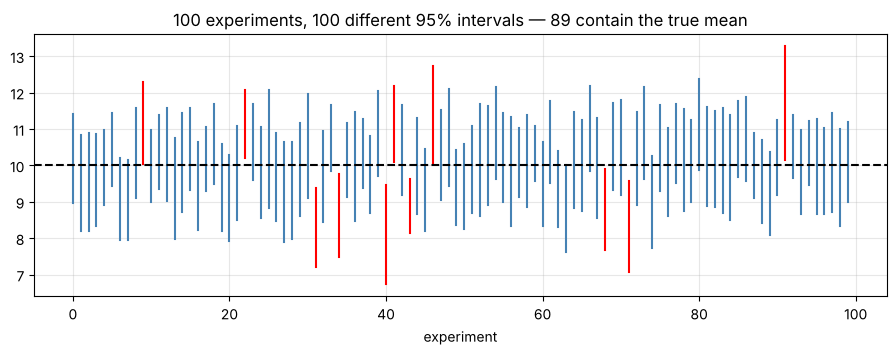

In [13]:
true_mu, n_obs = 10.0, 25
fig, ax = plt.subplots(figsize=(11, 3.4)); misses = 0
for k in range(100):
    x = rng.normal(true_mu, 3, n_obs)
    half = stats.t.ppf(0.975, n_obs - 1) * x.std(ddof=1) / np.sqrt(n_obs)    # t-interval: mean ± t × SE
    lo_, hi_ = x.mean() - half, x.mean() + half
    miss = not (lo_ <= true_mu <= hi_); misses += miss
    ax.plot([k, k], [lo_, hi_], c="r" if miss else "steelblue", lw=1.5)
ax.axhline(true_mu, c="k", ls="--"); ax.set_xlabel("experiment"); ax.set_title(f"100 experiments, 100 different 95% intervals — {100 - misses} contain the true mean")
plt.show()

**Standard error (SE)** = the standard deviation of an estimate across repeated samples. For a mean, $SE = s/\sqrt{n}$. Interval ≈ estimate ± 1.96 × SE (use the *t* distribution instead of 1.96 for small n).

### The bootstrap — confidence intervals for anything
What if there's no formula (a median, an AUC, a ratio)? **Bootstrap:** treat your sample as the population, **resample it with replacement** many times, recompute the statistic each time, and use the spread of those values.

In [14]:
revenue = rng.lognormal(3, 1.2, 300)                 # skewed, like real revenue-per-user data

# 🐍 Pure Python bootstrap of the median
def bootstrap_python(data, stat, n_boot=2000, seed=0):
    rnd = random.Random(seed); n = len(data)
    return sorted(stat([data[rnd.randrange(n)] for _ in range(n)]) for _ in range(n_boot))
def median_py(v):
    v = sorted(v); m = len(v) // 2
    return v[m] if len(v) % 2 else (v[m - 1] + v[m]) / 2
bs = bootstrap_python(revenue.tolist(), median_py)
print(f"pure Python: median {median_py(revenue.tolist()):.2f}, 95% CI [{bs[int(0.025 * 2000)]:.2f}, {bs[int(0.975 * 2000)]:.2f}]")

# 🔢 NumPy — all resamples at once
idx = rng.integers(0, len(revenue), (5000, len(revenue)))
boot_medians = np.median(revenue[idx], axis=1)
print(f"NumPy:       95% CI {np.percentile(boot_medians, [2.5, 97.5]).round(2)}")

# 📦 SciPy (uses the more accurate BCa method by default)
res = stats.bootstrap((revenue,), np.median, n_resamples=5000, random_state=0)
print(f"SciPy (BCa): 95% CI [{res.confidence_interval.low:.2f}, {res.confidence_interval.high:.2f}]")

pure Python: median 24.34, 95% CI [20.23, 28.83]
NumPy:       95% CI [19.87 28.78]
SciPy (BCa): 95% CI [19.62, 28.78]


## 6. Hypothesis testing

The logic, in steps:
1. **Null hypothesis H₀:** "there's no effect" (the new model is no better; the two groups have the same mean).
2. Choose a **test statistic** that would be extreme if H₀ were false (e.g. difference in means).
3. **p-value** = the probability of seeing a statistic **at least this extreme if H₀ were true**.
4. If p < α (commonly 0.05), **reject H₀**.

**What a p-value is NOT:** it's not the probability that H₀ is true, and it's not the size or importance of the effect. A tiny, useless effect can have p < 0.001 with enough data.

| Error | Meaning | Controlled by |
|---|---|---|
| **Type I** (false positive) | reject H₀ when it's true | α — the significance level |
| **Type II** (false negative) | miss a real effect | **power** = 1 − P(type II); grows with sample size and effect size |

### The permutation test — the most intuitive test
If H₀ is true (the group labels don't matter), then **shuffling the labels** shouldn't change anything. So shuffle many times, and see how often a shuffled difference is as large as the real one.

observed difference 2.50 | permutation p-value 0.2794


NumPy permutation p-value 0.2745


SciPy permutation_test p-value 0.2689
Note: we generated the data with a TRUE difference of 6, yet with only 40 users per group and this much noise,
the sample difference came out small and the test can't detect it. That's a Type II error from low POWER (Section 7).


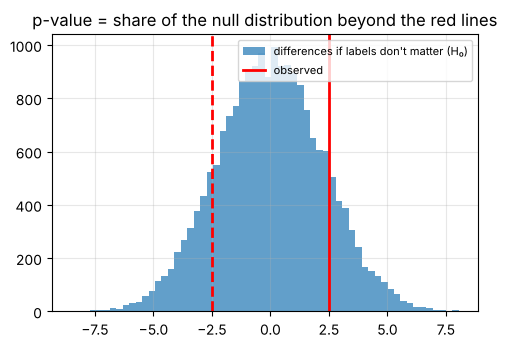

In [15]:
# Two groups: time-on-site for old vs new page design
old = rng.normal(50, 12, 40); new = rng.normal(56, 12, 40)
observed = new.mean() - old.mean()

# 🐍 Pure Python permutation test
def permutation_test_python(a, b, n_perm=10_000, seed=0):
    rnd = random.Random(seed); pooled = list(a) + list(b); na = len(a)
    obs = sum(b) / len(b) - sum(a) / na; extreme = 0
    for _ in range(n_perm):
        rnd.shuffle(pooled)
        diff = sum(pooled[na:]) / len(b) - sum(pooled[:na]) / na
        if abs(diff) >= abs(obs): extreme += 1
    return extreme / n_perm
print(f"observed difference {observed:.2f} | permutation p-value {permutation_test_python(old, new):.4f}")

# 🔢 NumPy, vectorised: 20,000 shuffles at once
pooled = np.concatenate([old, new])
perms = np.array([rng.permutation(pooled) for _ in range(20_000)])
diffs = perms[:, 40:].mean(1) - perms[:, :40].mean(1)
print(f"NumPy permutation p-value {np.mean(np.abs(diffs) >= abs(observed)):.4f}")

# 📦 SciPy
print(f"SciPy permutation_test p-value {stats.permutation_test((new, old), lambda x, y: x.mean() - y.mean(), n_resamples=20_000, random_state=0).pvalue:.4f}")
print("Note: we generated the data with a TRUE difference of 6, yet with only 40 users per group and this much noise,")
print("the sample difference came out small and the test can't detect it. That's a Type II error from low POWER (Section 7).")

plt.hist(diffs, bins=60, alpha=0.7, label="differences if labels don't matter (H₀)")
plt.axvline(observed, c="r", lw=2, label="observed"); plt.axvline(-observed, c="r", lw=2, ls="--")
plt.legend(fontsize=8); plt.title("p-value = share of the null distribution beyond the red lines"); plt.show()

### The t-test — the formula version
Welch's t-statistic compares the difference in means to its standard error:
$$ t = \frac{\bar x_B - \bar x_A}{\sqrt{s_A^2/n_A + s_B^2/n_B}} $$
Under H₀ it follows (approximately) a *t* distribution, which gives the p-value.

In [16]:
# 🔢 Welch's t-test by hand
se = np.sqrt(old.var(ddof=1) / len(old) + new.var(ddof=1) / len(new))
t_stat = (new.mean() - old.mean()) / se
dof = se**4 / ((old.var(ddof=1) / len(old))**2 / (len(old) - 1) + (new.var(ddof=1) / len(new))**2 / (len(new) - 1))   # Welch–Satterthwaite
p_val = 2 * stats.t.sf(abs(t_stat), dof)
print(f"by hand: t = {t_stat:.3f}, dof = {dof:.1f}, p = {p_val:.4f}")
r = stats.ttest_ind(new, old, equal_var=False)
print(f"SciPy:   t = {r.statistic:.3f}, p = {r.pvalue:.4f}")

by hand: t = 1.094, dof = 72.4, p = 0.2775
SciPy:   t = 1.094, p = 0.2775


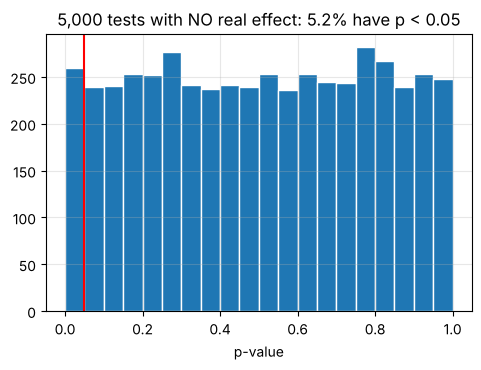

In [17]:
# Under H₀, p-values are uniformly distributed — so 5% of tests are "significant" by pure chance
null_p = [stats.ttest_ind(rng.normal(0, 1, 30), rng.normal(0, 1, 30)).pvalue for _ in range(5000)]
plt.hist(null_p, bins=20, edgecolor="white"); plt.axvline(0.05, c="r")
plt.title(f"5,000 tests with NO real effect: {np.mean(np.array(null_p) < 0.05):.1%} have p < 0.05"); plt.xlabel("p-value"); plt.show()

## 7. A/B testing

Show version A of a page to one random group and version B to another; compare the **conversion rates**. Randomisation is what makes the comparison causal: the only systematic difference between groups is the version.

### The two-proportion z-test
$$ z = \frac{\hat p_B - \hat p_A}{\sqrt{\hat p (1-\hat p)\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}, \qquad \hat p = \text{pooled conversion rate} $$

In [18]:
n_A, n_B = 5000, 5000
conv_A = rng.binomial(n_A, 0.100); conv_B = rng.binomial(n_B, 0.112)     # true rates 10.0% vs 11.2%
pA, pB = conv_A / n_A, conv_B / n_B; p_pool = (conv_A + conv_B) / (n_A + n_B)

# 🔢 by hand
z = (pB - pA) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_A + 1 / n_B))
p_two_sided = 2 * stats.norm.sf(abs(z))
se_diff = np.sqrt(pA * (1 - pA) / n_A + pB * (1 - pB) / n_B)
print(f"A: {pA:.2%}  B: {pB:.2%}  lift {pB - pA:+.2%} (95% CI {pB - pA - 1.96 * se_diff:+.2%} to {pB - pA + 1.96 * se_diff:+.2%})")
print(f"by hand: z = {z:.3f}, p = {p_two_sided:.4f}")

# 📦 statsmodels
from statsmodels.stats.proportion import proportions_ztest
zs, ps_ = proportions_ztest([conv_B, conv_A], [n_B, n_A])
print(f"statsmodels: z = {zs:.3f}, p = {ps_:.4f}")

A: 9.82%  B: 11.08%  lift +1.26% (95% CI +0.06% to +2.46%)
by hand: z = 2.059, p = 0.0395
statsmodels: z = 2.059, p = 0.0395


### Power and sample size — decide *before* running the test
How many users do we need to reliably detect a lift from 10% to 11% (a 1-point **minimum detectable effect**) with α = 0.05 and 80% power?
$$ n \text{ per group} \approx \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \,[p_A(1-p_A) + p_B(1-p_B)]}{(p_B - p_A)^2} $$

In [19]:
def sample_size(pA, pB, alpha=0.05, power=0.8):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return math.ceil((za + zb) ** 2 * (pA * (1 - pA) + pB * (1 - pB)) / (pB - pA) ** 2)

n_needed = sample_size(0.10, 0.11)
print(f"formula: {n_needed:,} users per group")
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
print(f"statsmodels: {math.ceil(NormalIndPower().solve_power(proportion_effectsize(0.11, 0.10), alpha=0.05, power=0.8)):,} per group (uses a slightly different effect-size scale)")

# 🔢 Check the power by simulation: run 2,000 experiments of that size where the effect is real
sims = 2000
cA = rng.binomial(n_needed, 0.10, sims); cB = rng.binomial(n_needed, 0.11, sims)
pa, pb = cA / n_needed, cB / n_needed; pp = (cA + cB) / (2 * n_needed)
zz = (pb - pa) / np.sqrt(pp * (1 - pp) * 2 / n_needed)
print(f"simulated power: {np.mean(2 * stats.norm.sf(np.abs(zz)) < 0.05):.1%} of experiments detect the effect (target 80%)")

formula: 14,749 users per group
statsmodels: 14,745 per group (uses a slightly different effect-size scale)
simulated power: 80.2% of experiments detect the effect (target 80%)


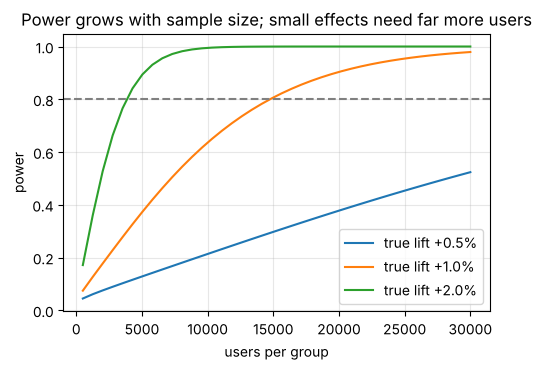

In [20]:
sizes = np.linspace(500, 30000, 40).astype(int)
for lift in [0.005, 0.01, 0.02]:
    za = stats.norm.ppf(0.975)
    se_ = np.sqrt(0.10 * 0.9 / sizes + (0.10 + lift) * (0.9 - lift) / sizes)
    plt.plot(sizes, stats.norm.sf(za - lift / se_), label=f"true lift +{lift:.1%}")
plt.axhline(0.8, ls="--", c="gray"); plt.xlabel("users per group"); plt.ylabel("power"); plt.legend()
plt.title("Power grows with sample size; small effects need far more users"); plt.show()

### The peeking problem
Checking the p-value every day and stopping as soon as p < 0.05 **inflates false positives** — with enough peeks, you'll eventually see a lucky dip. Simulate A/A tests (no real difference) with daily peeking:

In [21]:
n_experiments, days, per_day = 2000, 20, 500
false_pos_peek = false_pos_end = 0
for _ in range(n_experiments):
    a = rng.binomial(1, 0.1, days * per_day); b = rng.binomial(1, 0.1, days * per_day)    # NO real difference
    stopped = False
    for d in range(1, days + 1):
        m = d * per_day; pa_, pb_ = a[:m].mean(), b[:m].mean(); pp_ = (pa_ + pb_) / 2
        p = 2 * stats.norm.sf(abs(pb_ - pa_) / np.sqrt(pp_ * (1 - pp_) * 2 / m))
        if p < 0.05 and not stopped:
            false_pos_peek += 1; stopped = True
        if d == days and p < 0.05:
            false_pos_end += 1
print(f"false-positive rate, one test at the end:       {false_pos_end / n_experiments:.1%}  (≈ 5% as promised)")
print(f"false-positive rate, stop at first p < 0.05:     {false_pos_peek / n_experiments:.1%}  ← peeking breaks the guarantee")

false-positive rate, one test at the end:       4.5%  (≈ 5% as promised)
false-positive rate, stop at first p < 0.05:     25.3%  ← peeking breaks the guarantee


**Fixes:** fix the sample size in advance and test once; or use **sequential testing** methods designed for repeated looks (e.g. alpha-spending, mSPRT), or Bayesian decision rules.

## 8. Multiple testing

Test 20 metrics (or 20 user segments, or 20 model variants) at α = 0.05 and, even if nothing is real, you expect **one** false "win". The chance of at least one: $1 - 0.95^{20} \approx 64\%$.

- **Bonferroni:** use α/m for each of m tests. Controls the chance of *any* false positive (FWER). Very conservative.
- **Benjamini–Hochberg (BH):** controls the **false discovery rate** — the expected *fraction* of your "discoveries" that are false. More power; the standard for many tests.

**BH procedure:** sort the p-values $p_{(1)} \le \dots \le p_{(m)}$; find the largest k with $p_{(k)} \le \frac{k}{m}\alpha$; reject the hypotheses with the k smallest p-values.

In [22]:
# 50 metrics: 10 have a real effect, 40 don't
m_tests, n_real = 50, 10
pvals = np.array([stats.ttest_ind(rng.normal(0.5 if i < n_real else 0, 1, 50), rng.normal(0, 1, 50)).pvalue for i in range(m_tests)])
is_real = np.arange(m_tests) < n_real

# 🔢 BH by hand
def benjamini_hochberg(p, alpha=0.05):
    order = np.argsort(p); m = len(p)
    passed = p[order] <= alpha * np.arange(1, m + 1) / m
    k = np.max(np.where(passed)[0]) + 1 if passed.any() else 0
    reject = np.zeros(m, bool); reject[order[:k]] = True
    return reject

from statsmodels.stats.multitest import multipletests
for name, rej in [("no correction (p < 0.05)", pvals < 0.05), ("Bonferroni", pvals < 0.05 / m_tests),
                  ("Benjamini–Hochberg (ours)", benjamini_hochberg(pvals)), ("BH (statsmodels)", multipletests(pvals, method="fdr_bh")[0])]:
    print(f"{name:26s} discoveries {rej.sum():2d} | true {np.sum(rej & is_real):2d} | false {np.sum(rej & ~is_real):2d}")

no correction (p < 0.05)   discoveries  7 | true  4 | false  3
Bonferroni                 discoveries  2 | true  2 | false  0
Benjamini–Hochberg (ours)  discoveries  4 | true  4 | false  0
BH (statsmodels)           discoveries  4 | true  4 | false  0


## 9. Bayesian A/B testing

Instead of a p-value, compute what decision-makers actually want: **"What's the probability B is better than A, and by how much?"**

With a **Beta(1, 1)** (uniform) prior on each conversion rate and binomial data, the posterior is again a Beta (the prior is **conjugate**):
$$ p \mid \text{data} \sim \text{Beta}(1 + \text{conversions},\; 1 + \text{non-conversions}) $$
Sample from both posteriors and compare.

P(B better than A) = 0.980
expected lift +1.26%, 95% credible interval [+0.06%, +2.46%]
expected loss if we ship B (how much we lose in the worlds where A is better): 0.0044%


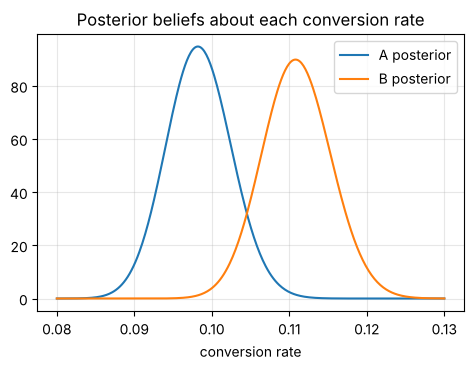

In [23]:
post_A = rng.beta(1 + conv_A, 1 + n_A - conv_A, 200_000)
post_B = rng.beta(1 + conv_B, 1 + n_B - conv_B, 200_000)
lift = post_B - post_A
print(f"P(B better than A) = {np.mean(lift > 0):.3f}")
print(f"expected lift {lift.mean():+.2%}, 95% credible interval [{np.percentile(lift, 2.5):+.2%}, {np.percentile(lift, 97.5):+.2%}]")
print(f"expected loss if we ship B (how much we lose in the worlds where A is better): {np.mean(np.maximum(-lift, 0)):.4%}")

g = np.linspace(0.08, 0.13, 400)
plt.plot(g, stats.beta(1 + conv_A, 1 + n_A - conv_A).pdf(g), label="A posterior")
plt.plot(g, stats.beta(1 + conv_B, 1 + n_B - conv_B).pdf(g), label="B posterior")
plt.xlabel("conversion rate"); plt.legend(); plt.title("Posterior beliefs about each conversion rate"); plt.show()

A **credible interval** *does* mean "95% probability the value is in here, given the model and prior" — the statement people often wrongly attach to confidence intervals.

## 10. Correlation is not causation — Simpson's paradox

A **confounder** affects both the "treatment" and the outcome and creates misleading associations. In the extreme, the overall trend can **reverse** within every subgroup.

*A hospital comparison:* Treatment A looks worse overall, but it's better for both mild and severe patients — because A is given mostly to severe cases.

In [24]:
import pandas as pd
rows = []
for severity, n_A_, n_B_, surv_A, surv_B in [("mild", 100, 800, 0.95, 0.90), ("severe", 900, 200, 0.60, 0.50)]:
    rows += [{"severity": severity, "treatment": "A", "patients": n_A_, "survived": round(n_A_ * surv_A)},
             {"severity": severity, "treatment": "B", "patients": n_B_, "survived": round(n_B_ * surv_B)}]
d = pd.DataFrame(rows)
by_group = d.assign(rate=d.survived / d.patients).pivot(index="severity", columns="treatment", values="rate")
overall = d.groupby("treatment")[["patients", "survived"]].sum(); overall["rate"] = overall.survived / overall.patients
print("survival rate within each group:\n", by_group.round(3), "\n\noverall:\n", overall["rate"].round(3))

survival rate within each group:
 treatment     A    B
severity            
mild       0.95  0.9
severe     0.60  0.5 

overall:
 treatment
A    0.635
B    0.820
Name: rate, dtype: float64


A wins in **both** groups but loses overall. The fix is to compare *within* levels of the confounder (or adjust for it in a model) — and the real gold standard is a **randomised experiment**, which breaks the link between confounders and treatment. This is also why feature importance and SHAP (notebook 10) describe the *model*, not causes.

## Key takeaways
- Simulate when in doubt: probability = long-run frequency.
- Bayes' rule: rare events + imperfect tests = mostly false alarms.
- LLN: averages converge. CLT: averages are ~normal with SE = σ/√n.
- Loss functions are negative log-likelihoods; priors are regularisers (MAP).
- A 95% CI is a *procedure* that captures the truth 95% of the time; the bootstrap gives CIs for anything.
- p-value = P(data this extreme | H₀). Not P(H₀), not effect size.
- A/B tests: compute sample size up front, don't peek, correct for multiple comparisons, and report effect sizes with intervals.
- Correlation ≠ causation; randomisation is how you get causation.

## Exercises
1. Simulate the **Monty Hall** problem: is switching doors better? Estimate both win rates.
2. Use the bootstrap to put a 95% CI on a model's **test AUC** (any model from notebooks 03–05).
3. Re-run the peeking simulation with peeks every 5 days instead of every day. How much does the false-positive rate fall?
4. How many users per group are needed to detect a lift from 2% to 2.2%? Why is it so many more than for 10% → 11%?

In [25]:
# Exercise 1 — solution
games = 100_000
car = rng.integers(0, 3, games); pick = rng.integers(0, 3, games)
print(f"stay wins {np.mean(car == pick):.3f} | switch wins {np.mean(car != pick):.3f}   (switching wins whenever the first pick was wrong: 2/3)")

stay wins 0.336 | switch wins 0.664   (switching wins whenever the first pick was wrong: 2/3)


In [26]:
# Exercise 4 — solution
print(f"2% → 2.2%: {sample_size(0.02, 0.022):,} per group vs 10% → 11%: {sample_size(0.10, 0.11):,}")
print("n scales with variance / lift². The lift is 5× smaller (0.2 vs 1 point) → 25× more users,")
print("but the variance p(1−p) at 2% is ~4.6× smaller than at 10% → overall ~5.5× more users.")

2% → 2.2%: 80,679 per group vs 10% → 11%: 14,749
n scales with variance / lift². The lift is 5× smaller (0.2 vs 1 point) → 25× more users,
but the variance p(1−p) at 2% is ~4.6× smaller than at 10% → overall ~5.5× more users.


**Next:** [14 · Linear Algebra & Calculus for ML](14_linear_algebra_and_calculus.ipynb) — the maths that makes models compute and learn.

*Going deeper / interview prep:* `Probability_Statistics_Notes.md` — everything here in more depth: Parts 1–2 (probability, distributions, LLN/CLT), 3 (estimation, bootstrap), 4–6 (intervals, tests, multiple testing), 8 (Bayesian), 9–10 (experiment design, causal inference), 11 (puzzles) · `ML_System_Design_Notes.md` §5.2 (A/B testing in production) · code: `stats_from_scratch.py`.